In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

file = "amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(file)
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [2]:
### Part 1: Understanding Product Categories

In [3]:
# What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

In [15]:
# 1. **Frequency Tables**:
# Generate a frequency table for the product `category`
frequency_table= df['category'].value_counts()

# Which are the top 5 most listed product categories?
top_5_categories = frequency_table.head(5)
print("Top 5 Categories:")
print(top_5_categories)

Top 5 Categories:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


In [5]:
Visualizations:

Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

SyntaxError: invalid syntax (1874591659.py, line 1)

In [17]:
# 1.calculate the counts to get the Top 10
top_10_categories = df['category'].value_counts().head(10)
print("Top 10 Categories for Visualization:")
print(top_10_categories)


Top 10 Categories for Visualization:
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64


C:\Users\davyg\AppData\Local\Temp\ipykernel_30168\2818474662.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(y=top_10_categories.index, x=top_10_categories.values, palette="Set3", legend=True )


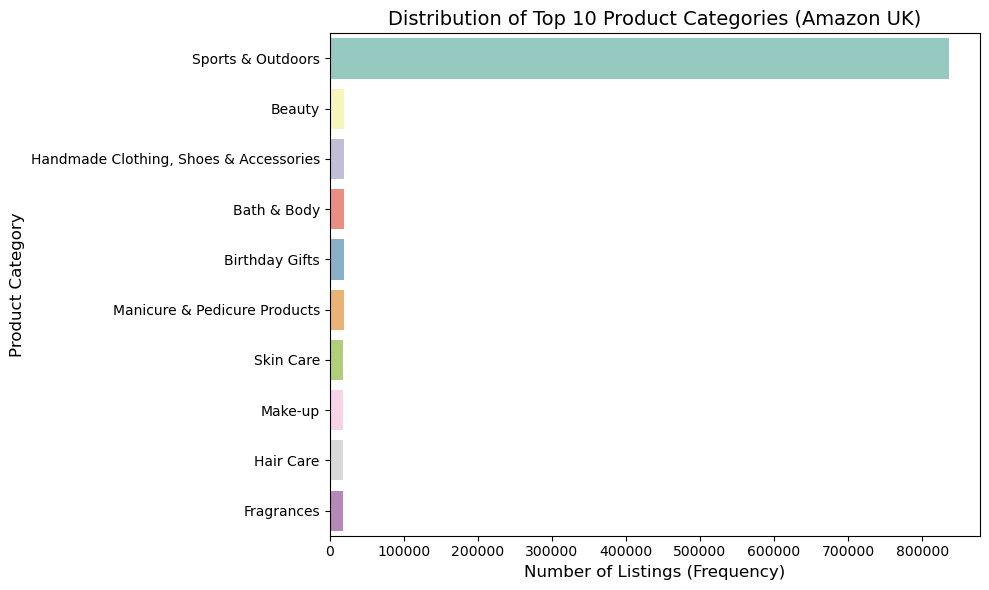

In [26]:
# 2. Plotting a bar chart using the values from the Top 10 Categories of frequency table, with colors sourced from the "Set3" palette
plt.figure(figsize=(10, 6)) 
ax=sns.barplot(y=top_10_categories.index, x=top_10_categories.values, palette="Set3", legend=True )


plt.title('Distribution of Top 10 Product Categories (Amazon UK)', fontsize=14)
plt.xlabel('Number of Listings (Frequency)', fontsize=12)
plt.ylabel('Product Category', fontsize=12)
# Display/Save the plot
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show() # Display the chart


In [38]:
# Calculating the proportion of each unique value in the 'top_10_categories'
proportion_table = (top_10_categories/top_10_categories.sum()).round(2)
proportion_table

category
Sports & Outdoors                         0.83
Beauty                                    0.02
Handmade Clothing, Shoes & Accessories    0.02
Bath & Body                               0.02
Birthday Gifts                            0.02
Manicure & Pedicure Products              0.02
Skin Care                                 0.02
Make-up                                   0.02
Hair Care                                 0.02
Fragrances                                0.02
Name: count, dtype: float64

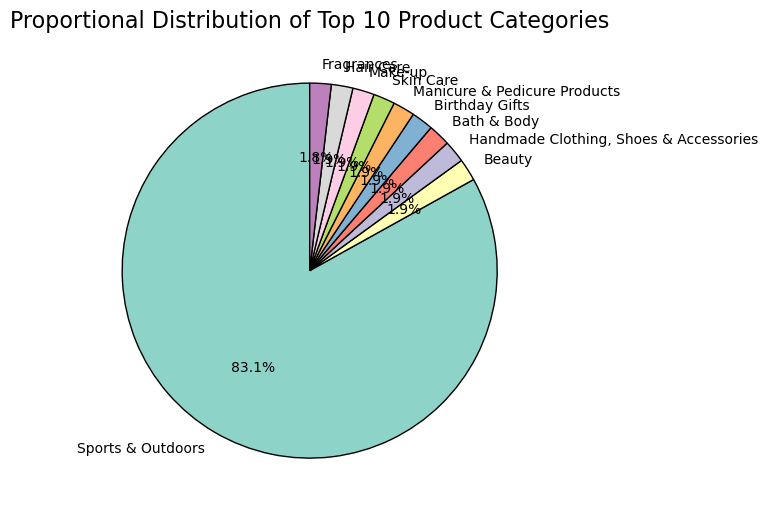

In [44]:
# 1. Create the figure/axes
plt.figure(figsize=(7, 7))

# 2. Plot the pie chart directly from the prepared Series
# The index provides the labels, and the values provide the size of the slices.
top_10_categories.plot.pie(
    autopct='%.1f%%',         
    startangle=90,              
    colors=sns.color_palette("Set3"),
    # Add borders to slices for clarity
    wedgeprops={'edgecolor': 'black'}, 
    legend=False,               
    label="",                   
)

# 3. Finalization
plt.title('Proportional Distribution of Top 10 Product Categories', fontsize=16)

plt.tight_layout()
plt.show() 


In [50]:
#Measures of Centrality**:
#Calculate the mean, median, and mode for the `price` of products.
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print("\nCentrality Measures for Product Price")
print(f"Mean Price (Average): {mean_price:.2f}")
print(f"Median Price (50th Percentile): {median_price:.2f}")
print(f"Mode Price (Most Common): {mode_price:.2f}")


Centrality Measures for Product Price
Mean Price (Average): 89.24
Median Price (50th Percentile): 19.09
Mode Price (Most Common): 9.99


#  What's the average price point of products listed? How does this compare with the most common price point (mode)?
Interpretation:
The average price point of products listed is £89.24.
The most common price point (mode : £9.99) is significantly lower than the average, it means that the most listings products are inexpensive

# Measures of Dispersion**:


In [54]:
# Determine the variance, standard deviation, range, and interquartile range for product `price`.
# 1. Calculate the core dispersion measures
variance_price = df['price'].var()
std_dev_price = df['price'].std()

# 2. Calculate the Range (Max - Min)
min_price = df['price'].min()
max_price = df['price'].max()
range_price = max_price - min_price

# 3. Calculate the Interquartile Range (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR_price = Q3 - Q1


print("Measures of Dispersion for product price")
print(f"Variance: {variance_price:,.2f}")
print(f"Standard Deviation: {std_dev_price:,.2f}")
print(f"Range (Max - Min): {range_price:,.2f}")
print(f"Interquartile Range (IQR): {IQR_price:,.2f}")


                                                                                


Measures of Dispersion for product price
Variance: 119,445.49
Standard Deviation: 345.61
Range (Max - Min): 100,000.00
Interquartile Range (IQR): 36.00


# How varied are the product prices? Are there any indicators of a significant spread in prices?
interpretation :
The standard Deviation (£345.61) is likely large relative to the Mean price (£89.24), indicating a high variability in pricing across the dataset.
The Range (£100,000.00) is very large, which is a strong indicator of extreme outliers (some very cheap and some very expensive products) in the Amazon UK listings.

# Visualizations

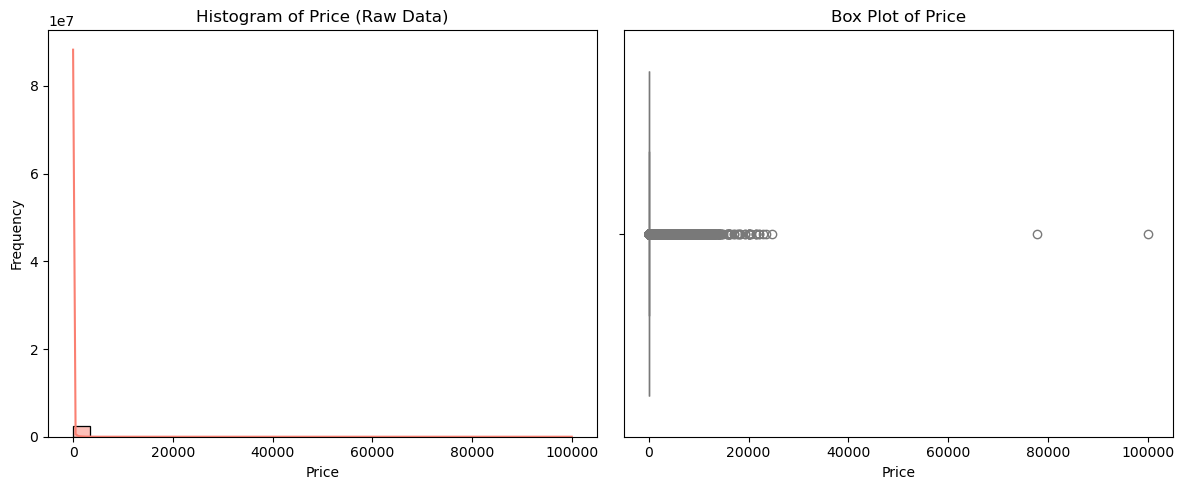


--- Interpretation ---
Histogram Suggestion: The distribution is heavily right-skewed (Price is concentrated near zero).
This means most products fall into the lowest price range, making the main body of the distribution hard to read.
Solution: Use a logarithmic transformation (e.g., np.log1p(df['price'])) to make the distribution more symmetrical and readable.

Box Plot Suggestion: The box plot confirms extreme outliers.
The box (IQR) is very narrow, located near zero, while the 'whiskers' and many individual points (outliers) extend far to the right.
This indicates that some products are priced SIGNIFICANTLY higher than the rest, confirming a large price spread.


In [61]:
# 1. Histogram Visualization (Raw Price)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1) # Setup for multiple plots
sns.histplot(df['price'], bins=30, color="salmon", kde=True)
plt.title('Histogram of Price (Raw Data)')
plt.xlabel('Price')
plt.ylabel('Frequency')

# 2. Box Plot Visualization (Outlier Detection)
plt.subplot(1, 2, 2)
sns.boxplot(x=df['price'], color="lightblue")
plt.title('Box Plot of Price')
plt.xlabel('Price')


plt.tight_layout()
plt.show() 



Interpretation
# Histogram Interpretation
Histogram Suggestion: The distribution is heavily right-skewed (Price is concentrated near zero).
This means most products fall into the lowest price range, making the main body of the distribution hard to read.
Solution: Use a logarithmic transformation like np.log1p(df['price]) to make the distribution more symmetrical and readable.

Box Plot Suggestion: 
The box plot confirms extreme outliers.
The box (IQR) is very narrow, located near zero, while the 'whiskers' and many individual points (outliers) extend far to the right.
This indicates that some products are priced SIGNIFICANTLY higher than the rest, confirming a large price spread.

In [62]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

# Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?
'stars'

In [66]:
#Calculate the mean, median, and mode for the `stars` of products.
mean_rate = df['stars'].mean()
median_rate = df['stars'].median()
mode_rate = df['stars'].mode()[0]

print("\nCentrality Measures for Product rating")
print(f"Mean Rating (Average): {mean_rate:.2f}")
print(f"Median Rating (50th Percentile): {median_rate:.2f}")
print(f"Mode Rating (Most Common): {mode_rate:.2f}")


Centrality Measures for Product rating
Mean Rating (Average): 2.15
Median Rating (50th Percentile): 0.00
Mode Rating (Most Common): 0.00


In [ ]:
Conclusion drawn from the EDA:
Extremely Negative Trend: The central tendency of the ratings is very low, with the median and mode at $0.00$.
Data Issue: Such a result is highly unusual for customer ratings (which generally range from 1.0 to 5.0). 
This strongly indicates that the value $0.00$ is not an actual rating, but rather a marker 
for products that have not yet been rated or for missing values that were replaced (imputed) by zero during the data extraction.


In [78]:
# Determine the variance, standard deviation, range, and interquartile range for product `stars`.
# 1. Calculate the core dispersion measures
variance_rate = df['stars'].var()
std_dev_rate = df['stars'].std()

# 2. Calculate the Range (Max - Min)
min_rate = df['stars'].min()
max_rate = df['stars'].max()
range_rate = max_price - min_price

# 3. Calculate the Interquartile Range (IQR)
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
IQR_rate = Q3 - Q1


print("Measures of Dispersion for product stars")
print(f"Variance: {variance_rate:,.2f}")
print(f"Standard Deviation: {std_dev_rate:,.2f}")
print(f"Range (Max - Min): {range_rate:,.2f}")
print(f"Interquartile Range (IQR): {IQR_rate:,.2f}")


Measures of Dispersion for product stars
Variance: 4.82
Standard Deviation: 2.19
Range (Max - Min): 5.00
Interquartile Range (IQR): 4.40


# Comparison and Interpretation (Example based on your previous output: Mode=0.00, Median=0.00)
Interpretation:
The Standard Deviation is likely high (due to the presence of 0.00 values).
This indicates a WIDE VARIATION in customer feedback and a lack of consistency.
This wide variation is primarily caused by products without ratings (coded as 0.00) and actual high ratings (4.5/5.0).
Conclusion: Ratings are NOT consistent; the data is highly dispersed and likely contains noise from unrated items.


# 3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [83]:
# 1. Calcul the Skewness
skewness_stars = df['stars'].skew()

# 2. Calculate the Kurtosis
kurtosis_stars = df['stars'].kurt()

# Display the result
print(f"Skewness of the ratings: {skewness_stars:.4f}")
print(f"Kurtosis of the ratings: {kurtosis_stars:.4f}")

# Quick interpretation explanation:
print("\n--- Interpretation ---")
if skewness_stars > 0:
    print(f"The distribution is positively skewed (Skewness = {skewness_stars:.2f}),")
    print("meaning the tail is pulled towards positive values (higher ratings).")
elif skewness_stars < 0:
    print(f"The distribution is negatively skewed (Skewness = {skewness_stars:.2f}),")
    print("meaning the tail is pulled towards negative values (lower ratings).")
else:
    print("The distribution is approximately symmetric.")

if kurtosis_stars > 0:
    # Adding an image tag here to help visualize the concept
    print(f"The distribution is leptokurtic (Kurtosis = {kurtosis_stars:.2f}),")
    print("it is more peaked than a normal distribution (more data concentrated around the peak).")
elif kurtosis_stars < 0:
    print(f"The distribution is platykurtic (Kurtosis = {kurtosis_stars:.2f}),")
    print("it is flatter than a normal distribution (less concentration around the peak).")
else:
    print("The distribution is mesokurtic (similar to a normal distribution).")

#

Skewness of the ratings: 0.0812
Kurtosis of the ratings: -1.9260

--- Interpretation ---
The distribution is positively skewed (Skewness = 0.08),
meaning the tail is pulled towards positive values (higher ratings).
The distribution is platykurtic (Kurtosis = -1.93),
it is flatter than a normal distribution (less concentration around the peak).


In [ ]:
Interpreattion :
The distribution is positively skewed (Skewness = 0.08), meaning the tail is pulled towards positive value (higher ratings).
the distribution is platykurtic (kurtosis = -1.93), it is flatter than a normal distribution (less concentration around the peak).

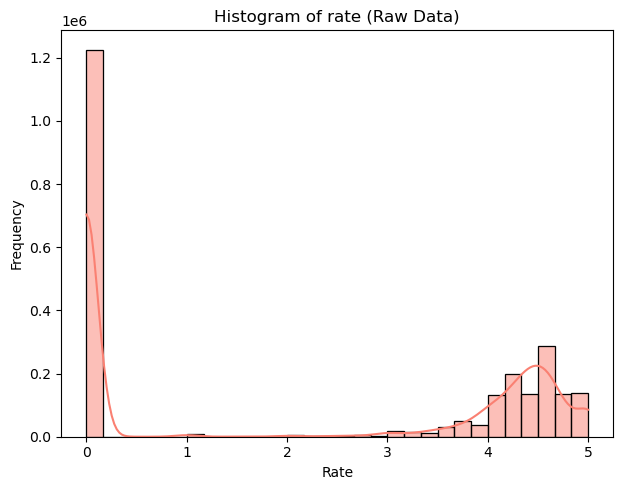

In [84]:
# 1. Histogram Visualization (Raw Price)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1) # Setup for multiple plots
sns.histplot(df['stars'], bins=30, color="salmon", kde=True)
plt.title('Histogram of rate (Raw Data)')
plt.xlabel('Rate')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show() 

Interpretation

Skewness:
The distribution is highly positively skewed. This skewness is driven by the vast concentration of data at the minimum value (0.00), 
with a long tail extending towards the higher, positive rating values (4.0-5.0).

Kurtosis :
The distribution is leptokurtic (very peaked). This indicates that the majority of observations are heavily concentrated around one value (the 0.00 mode),
and the tails (where the real 5.0 ratings are) are "heavy" meaning extreme values are more common than in a normal distribution.

Conclusion on the Rating Distribution
Trend: The rating distribution is NON-NORMAL and severely asymmetric.

Bias: The asymmetry is caused by the extreme concentration of data at the minimum value (likely representing unrated products imputed as 0.00) 
and the presence of a strong tail of higher ratings (representing actual customer satisfaction).

Significance: The high Kurtosis confirms that the dataset is dominated by one spike (the 0.00 values) 
and that the true high ratings are present in heavy tails, showing a dual nature in the data.